<a href="https://colab.research.google.com/github/aromaric21/7688581-Expert-Git-GitHub/blob/main/projet_classification_ml.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. Collecte - Chargement des données

In [ ]:
import pandas as pd
URL=("https://raw.githubusercontent.com/formation-ia-data/classification-eleves-python/v1/data/student-mat.csv")
df=pd.read_csv(URL,sep=";")
df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [ ]:
df.head(2)

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6


2. Exploration

In [ ]:
df.head(3)

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nursery     395 non-null    object
 20  higher    

In [ ]:
# Valeur manquante
df.isna().sum().sum()

np.int64(0)

In [ ]:

df[["school", "age", "studytime", "failures", "G1", "G2", "G3"]].head()

,school,age,studytime,failures,G1,G2,G3
0,GP,18,2,0,5,6,6
1,GP,17,2,0,5,5,6
2,GP,15,2,3,7,8,10
3,GP,15,3,0,15,14,15
4,GP,16,2,0,6,10,10


La variable cible.
Un élève est en échec si sa note finale est inférieure à 10.

In [ ]:
df["echec"] = (df["G3"] < 10).astype(int)
df["echec"].value_counts()

,count
echec,
0,265
1,130


In [ ]:
df["echec"].value_counts(normalize=True).round(3)

,proportion
echec,
0,0.671
1,0.329


3. Nettoyage : Aucune valeur manquante. Le jeu est-il propre pour autant

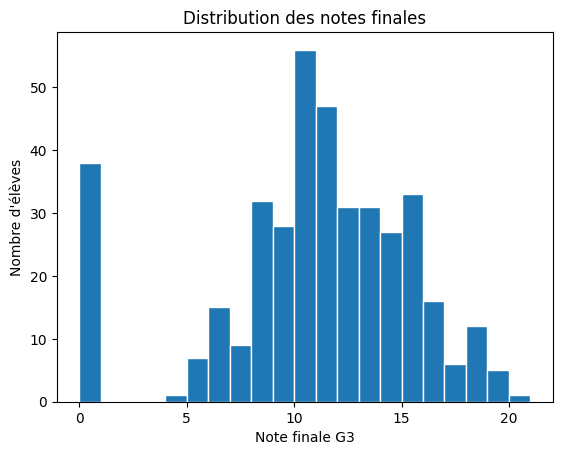

In [ ]:
import matplotlib.pyplot as plt
plt.hist(df["G3"], bins=range(0, 22), edgecolor="white")
plt.xlabel("Note finale G3")
plt.ylabel("Nombre d'élèves")
plt.title("Distribution des notes finales")
plt.show()

Une barre isolée à 0, et **personne entre 1 et 3**. Regardons ces élèves.

In [ ]:
zeros = df[df["G3"] ==0]
len(zeros)

38

In [ ]:
zeros[["G1", "G2", "G3", "absences"]].describe()

,G1,G2,G3,absences
count,38.000000,38.000000,38.0,38.0
mean,7.526316,4.657895,0.0,0.0
std,1.811925,3.700083,0.0,0.0
min,4.000000,0.000000,0.0,0.0
25%,6.000000,0.000000,0.0,0.0
50%,7.000000,5.000000,0.0,0.0
75%,9.000000,8.000000,0.0,0.0
max,12.000000,10.000000,0.0,0.0


Comparons avec les autres élèves en échec, ceux qui ont une finale de 1 à 9

In [ ]:
autre_echecs = df[(df["G3"] > 0) & (df["G3"] < 10)]
print("Notes finale à 0 :", len(zeros), "élèves", round(zeros["absences"].mean(), 1), "absences moyennes,",
      f"{(zeros['absences']==0).mean():.0%} à zéro absence")
print("Note finale de 1 à 9 :", len(autre_echecs), "élèves", round(autre_echecs["absences"].mean(), 1), "absences moyennes,",
      f"{(autre_echecs['absences']==0).mean():.0%} à zéro absence")

Notes finale à 0 : 38 élèves 0.0 absences moyennes, 100% à zéro absence
Note finale de 1 à 9 : 92 élèves 9.6 absences moyennes, 13% à zéro absence


In [ ]:
sans_zeros = df[df["G3"] > 0]
print("Modèle naif, avec les 38 :", f"{1 - df['echec'].mean():.1%}")
print("Modèle naif, sans les 38 :", f"{1 - sans_zeros['echec'].mean():.1%}")

Modèle naif, avec les 38 : 67.1%
Modèle naif, sans les 38 : 74.2%


In [ ]:
df["failures"].value_counts().sort_index()

,count
failures,
0,312
1,50
2,17
3,16



4. Exploration et prétraitement

In [ ]:
colonnes = ["school","age","studytime","failures","internet","G1"]
X= df[colonnes].copy()
y= df["echec"]

# Encodage binaire, comme l'exemple du fumeur dans le cours.
# Il n'apprend rien des données : on peut le faire avant le découpage.
X["internet"] = (X["internet"] == "yes").astype(int)
X["school"] = (X["school"] == "MS").astype(int)
X.head()

,school,age,studytime,failures,internet,G1
0,0,18,2,0,0,5
1,0,17,2,0,1,5
2,0,15,2,3,1,7
3,0,15,3,0,1,15
4,0,16,2,0,0,6


In [ ]:
from sklearn.model_selection import train_test_split
X_tmp, X_test, y_tmp, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(X_tmp, y_tmp, test_size=0.25, random_state=42, stratify=y_tmp)
#

In [ ]:
for nom, cible in [("apprentissage", y_train), ("validation", y_val), ("test", y_test)]:
    nb_zeros = (df.loc[cible.index, "G3"] == 0).sum()
    print(f"{nom:14s}: {len(cible)} élèves, {cible.sum()} échecs ({cible.mean():.1%}),"
          f" dont {nb_zeros} à 0")

apprentissage : 237 élèves, 78 échecs (32.9%), dont 23 à 0
validation    : 79 élèves, 26 échecs (32.9%), dont 7 à 0
test          : 79 élèves, 26 échecs (32.9%), dont 8 à 0


##4c. Explorer, sur l'apprentissage seulement

In [ ]:
appr = df.loc[X_train.index]
appr.groupby("failures")["echec"].agg(["mean", "count"]).round(2)

,mean,count
failures,,
0,0.27,192
1,0.50,30
2,0.88,8
3,0.71,7


In [ ]:
appr[["G1", "G2", "G3"]].corr()["G3"].round(3)

,G3
G1,0.777
G2,0.887
G3,1.000


`G2` est encore plus liée à la note finale que `G1`. Mais à la fin du premier trimestre,
**on ne la connaît pas** : l'utiliser serait une **fuite de cible**.

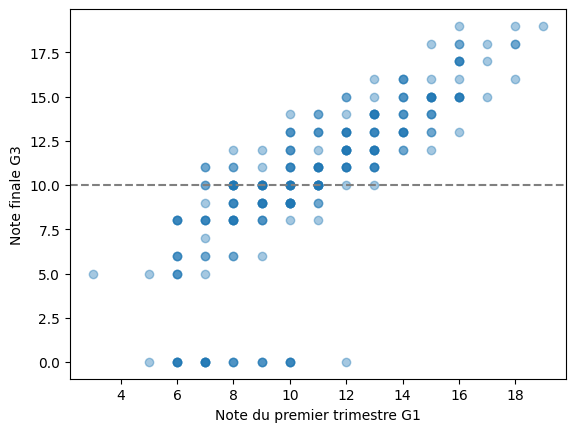

In [ ]:
plt.scatter(appr["G1"], appr["G3"], alpha=0.4)
plt.axhline(10, color="grey", linestyle="--")
plt.xlabel("Note du premier trimestre G1")
plt.ylabel("Note finale G3")
plt.show()

##4d. Standardiser

In [ ]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler().fit(X_train)
#scaler = StandardScaler()
#scaler.fit(X_train)
X_train_scaled = scaler.transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

## 5. Modélisation — entraîner une régression logistique

Classe positive = **échec** (1) : « positif » désigne ce qu'on cherche à repérer,
pas une bonne nouvelle.

In [ ]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression()
model.fit(X_train_scaled, y_train)

proba_val = model.predict_proba(X_val_scaled)[:, 1] # probabilité d'échec estimé
pred_val = model.predict(X_val_scaled)              # seuil de 0,5

`predict_proba` applique la **fonction sigmoïde** : elle transforme un score en
**probabilité estimée par le modèle**. Quelques élèves de la validation :

In [ ]:
apercu = df.loc[X_val.index, ["G1", "failures", "studytime", "echec"]].copy()
apercu["proba_echec"] = proba_val.round(2)
apercu.head(8)

,G1,failures,studytime,echec,proba_echec
11,10,0,3,0,0.22
132,10,0,1,0,0.27
271,15,0,4,0,0.02
65,16,0,2,0,0.00
196,17,0,1,0,0.00
340,11,1,3,0,0.46
254,8,0,1,0,0.65
344,11,0,3,0,0.30


`predict` déclare « échec » dès que cette probabilité atteint **0,5**.
Ce seuil est un **choix**, pas une loi.

Les coefficients : on lit leur **signe**, pas leur valeur exacte.

In [ ]:
pd.Series(model.coef_[0], index=colonnes).round(2).sort_values()

,0
G1,-2.58
school,-0.26
internet,-0.11
failures,0.16
studytime,0.24
age,0.51


## 6. Interprétation — évaluer, régler le seuil, comparer

### 6a. Sur la validation

Une petite fonction pour ne pas répéter les mêmes lignes à chaque modèle.
Elle traduit les mesures **en élèves**.

In [ ]:
import numpy as np
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay)

def bilan(nom, y_vrai, y_pred):
    vn, fp, fn, vp = confusion_matrix(y_vrai, y_pred, labels=[0, 1]).ravel()
    print(nom)
    print(f"  taux de bonne prédiction : {accuracy_score(y_vrai, y_pred):.1%}")
    print(f"  rappel (échec)           : {vp} élèves repérés sur {vp + fn} en échec"
          f" ({recall_score(y_vrai, y_pred, zero_division=0):.1%})")
    if vp + fp > 0:
        print(f"  précision (échec)        : {vp} vrais échecs sur {vp + fp} alertes"
              f" ({precision_score(y_vrai, y_pred):.1%})")
    else:
        print("  précision (échec)        : non définie, aucune alerte (0 par convention)")
    print(f"  score F1 (échec)         : {f1_score(y_vrai, y_pred, zero_division=0):.3f}")
    print(f"  fausses alertes : {fp} · élèves manqués : {fn}")

In [ ]:
pred_naif_val = np.zeros(len(y_val), dtype=int)     # « tout le monde réussit »

bilan("Modèle naïf", y_val, pred_naif_val)
bilan("Régression logistique, seuil 0,5", y_val, pred_val)

Modèle naïf
  taux de bonne prédiction : 67.1%
  rappel (échec)           : 0 élèves repérés sur 26 en échec (0.0%)
  précision (échec)        : non définie, aucune alerte (0 par convention)
  score F1 (échec)         : 0.000
  fausses alertes : 0 · élèves manqués : 26
Régression logistique, seuil 0,5
  taux de bonne prédiction : 89.9%
  rappel (échec)           : 25 élèves repérés sur 26 en échec (96.2%)
  précision (échec)        : 25 vrais échecs sur 32 alertes (78.1%)
  score F1 (échec)         : 0.862
  fausses alertes : 7 · élèves manqués : 1


Le modèle naïf a un taux de bonne prédiction honorable… et **ne repère aucun élève en échec**.

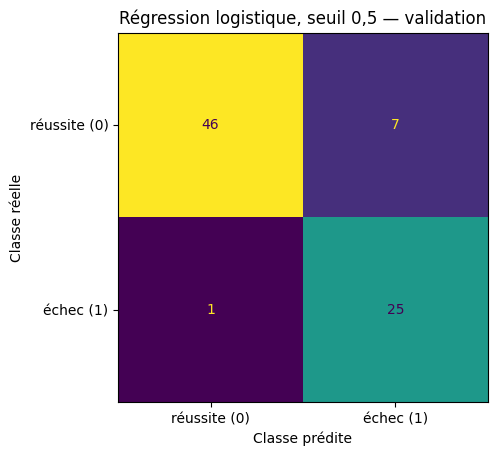

In [ ]:
ConfusionMatrixDisplay.from_predictions(
    y_val, pred_val, display_labels=["réussite (0)", "échec (1)"], colorbar=False)
plt.xlabel("Classe prédite")
plt.ylabel("Classe réelle")
plt.title("Régression logistique, seuil 0,5 — validation")
plt.show()

### Le modèle « tricheur » : avec `G2`

Même chose, en ajoutant la note du deuxième trimestre :

In [ ]:
X_g2 = X.copy()
X_g2["G2"] = df["G2"]

scaler_g2 = StandardScaler().fit(X_g2.loc[X_train.index])
modele_g2 = LogisticRegression().fit(scaler_g2.transform(X_g2.loc[X_train.index]), y_train)
pred_g2_val = modele_g2.predict(scaler_g2.transform(X_g2.loc[X_val.index]))

bilan("Régression logistique AVEC G2, seuil 0,5", y_val, pred_g2_val)

Régression logistique AVEC G2, seuil 0,5
  taux de bonne prédiction : 92.4%
  rappel (échec)           : 25 élèves repérés sur 26 en échec (96.2%)
  précision (échec)        : 25 vrais échecs sur 30 alertes (83.3%)
  score F1 (échec)         : 0.893
  fausses alertes : 5 · élèves manqués : 1


Quel que soit ce score, ce modèle est **inutile** : quand on connaît `G2`, l'année est
presque finie.
**Un score élevé n'est pas une preuve d'utilité.**

### 6b. Régler le seuil, sur la validation

**Objectif fixé avant le calcul :** repérer au moins 8 élèves en échec sur 10 (rappel ≥ 80 %),
avec le moins de fausses alertes possible (la meilleure précision).
À précision égale, on prend le rappel le plus élevé, puis le seuil qui déclenche le moins
d'alertes.

Ce rappel de 80 % est un **objectif de réglage sur la validation**, pas une performance
promise sur le test.

In [ ]:
def choisir_seuil(y_vrai, predictions_par_seuil):
    candidats = []
    for seuil, pred in predictions_par_seuil.items():
        rappel = recall_score(y_vrai, pred)
        if rappel >= 0.80:
            precision = precision_score(y_vrai, pred, zero_division=0)
            candidats.append((precision, rappel, -pred.sum(), seuil))
    return max(candidats)[3]

On applique **la même règle** à deux concurrents :
- la régression logistique, avec un seuil sur la probabilité estimée ;
- la **note `G1` seule** : « alerte si `G1` < c ». `G1` est déjà un score : on peut aussi
  déplacer son seuil.

In [ ]:
from sklearn.metrics import precision_recall_curve

_, _, seuils = precision_recall_curve(y_val, proba_val)
seuil_reg = choisir_seuil(
    y_val, {s: (proba_val >= s).astype(int) for s in seuils}
)

notes = sorted(X_val["G1"].unique())
c_g1 = choisir_seuil(
    y_val, {c: (X_val["G1"] < c).astype(int).to_numpy() for c in notes}
)

print("Seuil retenu pour la régression :", round(seuil_reg, 3))
print("Seuil retenu pour G1            : alerte si G1 <", c_g1)

Seuil retenu pour la régression : 0.689
Seuil retenu pour G1            : alerte si G1 < 9


In [ ]:
bilan(f"Régression logistique, seuil {seuil_reg:.2f}", y_val,
      (proba_val >= seuil_reg).astype(int))
bilan(f"Note G1 seule, alerte si G1 < {c_g1}", y_val,
      (X_val["G1"] < c_g1).astype(int))

Régression logistique, seuil 0.69
  taux de bonne prédiction : 87.3%
  rappel (échec)           : 21 élèves repérés sur 26 en échec (80.8%)
  précision (échec)        : 21 vrais échecs sur 26 alertes (80.8%)
  score F1 (échec)         : 0.808
  fausses alertes : 5 · élèves manqués : 5
Note G1 seule, alerte si G1 < 9
  taux de bonne prédiction : 88.6%
  rappel (échec)           : 23 élèves repérés sur 26 en échec (88.5%)
  précision (échec)        : 23 vrais échecs sur 29 alertes (79.3%)
  score F1 (échec)         : 0.836
  fausses alertes : 6 · élèves manqués : 3


Abaisser le seuil repère plus d'élèves, au prix de plus de fausses alertes.
Une fausse alerte a un coût : du temps d'enseignant, et un élève étiqueté « à risque » à tort.

### 6c. L'évaluation finale, sur le test

Les seuils sont **figés**. On ne les déplace plus.

In [ ]:
proba_test   = model.predict_proba(X_test_scaled)[:, 1]
pred_naif    = np.zeros(len(y_test), dtype=int)
pred_g1      = (X_test["G1"] < c_g1).astype(int)
pred_reg     = (proba_test >= seuil_reg).astype(int)

bilan("Modèle naïf", y_test, pred_naif)
bilan(f"Note G1 seule, alerte si G1 < {c_g1}", y_test, pred_g1)
bilan(f"Régression logistique, seuil {seuil_reg:.2f}", y_test, pred_reg)

Modèle naïf
  taux de bonne prédiction : 67.1%
  rappel (échec)           : 0 élèves repérés sur 26 en échec (0.0%)
  précision (échec)        : non définie, aucune alerte (0 par convention)
  score F1 (échec)         : 0.000
  fausses alertes : 0 · élèves manqués : 26
Note G1 seule, alerte si G1 < 9
  taux de bonne prédiction : 81.0%
  rappel (échec)           : 15 élèves repérés sur 26 en échec (57.7%)
  précision (échec)        : 15 vrais échecs sur 19 alertes (78.9%)
  score F1 (échec)         : 0.667
  fausses alertes : 4 · élèves manqués : 11
Régression logistique, seuil 0.69
  taux de bonne prédiction : 83.5%
  rappel (échec)           : 15 élèves repérés sur 26 en échec (57.7%)
  précision (échec)        : 15 vrais échecs sur 17 alertes (88.2%)
  score F1 (échec)         : 0.698
  fausses alertes : 2 · élèves manqués : 11


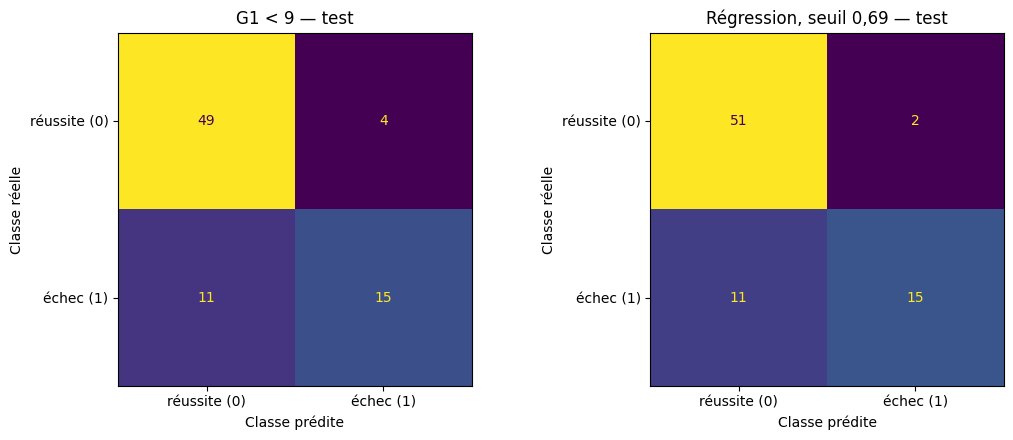

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, pred, titre in [(axes[0], pred_g1, f"G1 < {c_g1}"),
                        (axes[1], pred_reg, f"Régression, seuil {seuil_reg:.2f}".replace(".", ","))]:
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred, display_labels=["réussite (0)", "échec (1)"],
        ax=ax, colorbar=False
    )
    ax.set_xlabel("Classe prédite")
    ax.set_ylabel("Classe réelle")
    ax.set_title(titre + " — test")
plt.tight_layout()
plt.show()

Le test ne compte qu'une **vingtaine d'échecs** : un seul élève fait bouger le rappel de
près de 4 points. Si les deux méthodes sont proches, ou donnent des compromis différents,
**on ne désigne pas de vainqueur**.

### 6d. Et sans les 38 élèves à 0 ?

On garde **les mêmes ensembles**, et on retire les élèves à 0 à l'intérieur de chacun.
Puis on refait tout : standardisation, modèle, réglage des seuils sur la validation,
évaluation sur le test.

In [ ]:
def sans_les_zeros(X_, y_):
    garder = (df.loc[X_.index, "G3"] > 0).to_numpy()
    return X_[garder], y_[garder]

X_train_f, y_train_f = sans_les_zeros(X_train, y_train)
X_val_f,   y_val_f   = sans_les_zeros(X_val, y_val)
X_test_f,  y_test_f  = sans_les_zeros(X_test, y_test)

scaler_f = StandardScaler().fit(X_train_f)
modele_f = LogisticRegression().fit(scaler_f.transform(X_train_f), y_train_f)

proba_val_f = modele_f.predict_proba(scaler_f.transform(X_val_f))[:, 1]
_, _, seuils_f = precision_recall_curve(y_val_f, proba_val_f)
seuil_reg_f = choisir_seuil(
    y_val_f, {s: (proba_val_f >= s).astype(int) for s in seuils_f}
)
c_g1_f = choisir_seuil(
    y_val_f, {c: (X_val_f["G1"] < c).astype(int).to_numpy()
              for c in sorted(X_val_f["G1"].unique())}
)

proba_test_f = modele_f.predict_proba(scaler_f.transform(X_test_f))[:, 1]
bilan(f"SANS LES ZÉROS — G1 < {c_g1_f}", y_test_f, (X_test_f["G1"] < c_g1_f).astype(int))
bilan(f"SANS LES ZÉROS — régression, seuil {seuil_reg_f:.2f}", y_test_f,
      (proba_test_f >= seuil_reg_f).astype(int))

SANS LES ZÉROS — G1 < 9
  taux de bonne prédiction : 83.1%
  rappel (échec)           : 10 élèves repérés sur 18 en échec (55.6%)
  précision (échec)        : 10 vrais échecs sur 14 alertes (71.4%)
  score F1 (échec)         : 0.625
  fausses alertes : 4 · élèves manqués : 8
SANS LES ZÉROS — régression, seuil 0.46
  taux de bonne prédiction : 84.5%
  rappel (échec)           : 12 élèves repérés sur 18 en échec (66.7%)
  précision (échec)        : 12 vrais échecs sur 17 alertes (70.6%)
  score F1 (échec)         : 0.686
  fausses alertes : 5 · élèves manqués : 6


Le coefficient de `G1`, **ramené à un point de note** (le coefficient standardisé change
d'unité quand l'écart-type change) :

In [ ]:
i = colonnes.index("G1")
print("Avec les 38 :", round(model.coef_[0][i] / scaler.scale_[i], 3), "par point de G1")
print("Sans les 38 :", round(modele_f.coef_[0][i] / scaler_f.scale_[i], 3), "par point de G1")

Avec les 38 : -0.816 par point de G1
Sans les 38 : -0.798 par point de G1


---
### Complément — la variabilité des mesures

Une **validation croisée descriptive**, sur l'apprentissage et la validation réunis
(**jamais le test**), au seuil par défaut de 0,5. Elle ne choisit ni seuil ni modèle, et ne
change pas la conclusion : elle montre seulement combien les mesures varient d'un découpage
à l'autre. Le `make_pipeline` refait la standardisation à l'intérieur de chaque pli, pour
éviter toute fuite.

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline

X_av = pd.concat([X_train, X_val])
y_av = pd.concat([y_train, y_val])

resultats_cv = cross_validate(
    make_pipeline(StandardScaler(), LogisticRegression()),
    X_av, y_av,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring=["accuracy", "precision", "recall"],
)
pd.DataFrame(resultats_cv)[["test_accuracy", "test_precision", "test_recall"]] \
    .describe().loc[["mean", "min", "max"]].round(3)

,test_accuracy,test_precision,test_recall
mean,0.851,0.793,0.750
min,0.825,0.727,0.619
max,0.889,0.842,0.810


---
### Versions utilisées pour la vidéo

Si le notebook ne fonctionne plus un jour, cette cellule indique avec quelles versions
la vidéo a été tournée.

In [ ]:
import pandas, sklearn, matplotlib, sys
print(sys.version)
print("pandas", pandas.__version__, "| sklearn", sklearn.__version__,
      "| matplotlib", matplotlib.__version__)

3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
pandas 2.2.3 | sklearn 1.6.1 | matplotlib 3.10.0
